# Dokumentasi Pipeline Preprocessing Dataset — Deteksi Jatuh Panti Jompo

Notebook ini menjelaskan, berurutan dan apa adanya, preprocessing yang **benar-benar dipakai** untuk
membuat dataset training final dari dua sumber: **UR Fall (cam0)** dan **MCF (Multiple Cameras Fall Dataset)**.

> **Catatan penting tentang bentuk pipeline.** Pipeline final **bukan satu skrip tunggal dengan satu konfigurasi**.
> Ia terdiri dari lima skrip berurutan di `ml/scripts/` (branch `ml-modeling`). Parameter tiap tahap diberikan
> lewat argumen CLI masing-masing dan dicatat di `dataset_manifest.json` tahap itu. Notebook ini mengikuti
> struktur tersebut dan merangkum seluruh parameternya di satu tabel pada bagian 8.

**Cara membaca.** Setiap tahap berisi: (1) narasi: masukan, proses, keluaran, dan alasan desain;
(2) **kode asli** yang ditampilkan lewat `inspect.getsource`, bukan salinan, sehingga selalu sama dengan skrip;
(3) angka dari manifest atau `frames_meta.csv`. Notebook ini **hanya membaca**: tidak ada data, label, atau
skrip yang diubah, dan tidak ada pemrosesan berat yang dijalankan ulang.

## Peta alur

```
Data mentah                            Tahap                                      Keluaran
-------------------------------------  -----------------------------------------  ---------------------------------
MCF technical report (PDF)         --> 0. extract_mcf_tables.py (+ mcf_check.py) --> ml/data/mcf/annotations.csv, frame_delay.csv
UR Fall cam0 (ZIP PNG + CSV label) --> 1. prepare_dataset.py                    --> ml/data/processed
MCF (AVI: 24 skenario x 8 kamera)  --> 2. prepare_mcf.py                        --> ml/data/processed_mcf
                                       3. merge_datasets.py                     --> ml/data/processed_v2
                                       4. audit_dataset.py   (read-only)        --> processed_v2/frames_meta.csv
                                       5. make_training_set.py                  --> ml/data/processed_v2_3cls  (DATASET FINAL)
```

| Tahap | Skrip | Tugas singkat |
|---|---|---|
| 0 | `extract_mcf_tables.py`, `mcf_check.py` | Mengambil tabel anotasi dan delay MCF dari PDF (dengan erratum), memeriksa sinkronisasi kamera secara visual |
| 1 | `prepare_dataset.py` | UR Fall → YOLO: stride per kelas, bbox otomatis, split per video |
| 2 | `prepare_mcf.py` | MCF → YOLO: segmen anotasi → frame, guard band, stride, sinkronisasi 8 kamera, filter objek statis, split per skenario |
| 3 | `merge_datasets.py` | Menggabungkan dua dataset tanpa mengacak ulang split (dengan opsi memindahkan skenario MCF antar-split) |
| 4 | `audit_dataset.py` | Audit read-only sebelum training; menulis `frames_meta.csv` |
| 5 | `make_training_set.py` | Koreksi label ADL berbaring, subsampling transitional di train, keluaran 3 kelas final |

**Tiga kelas** di seluruh pipeline: `0 = normal`, `1 = transitional` (fase jatuh), `2 = lying_on_ground`.

## 1. Persiapan

Sel berikut menyiapkan jalur repo, gaya grafik, dan fungsi bantu. `load_script` memuat skrip di `ml/scripts/`
sebagai modul (tanpa menjalankan `main`) agar kode yang ditampilkan di bawah adalah kode asli.
Warna kelas konsisten di semua grafik: biru = normal, oranye = transitional, aqua = lying.

In [1]:
import sys, json, inspect, importlib.util, warnings, random
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

sys.dont_write_bytecode = True   # jangan menulis __pycache__ ke repo

try:
    from IPython.display import display
except ImportError:              # dijalankan di luar Jupyter
    def display(obj):
        print(obj.to_string() if hasattr(obj, "to_string") else obj)


def find_root(start=None):
    start = Path(start or Path.cwd()).resolve()
    for p in [start, *start.parents]:
        if (p / "ml" / "scripts").is_dir():
            return p
    raise FileNotFoundError("Jalankan notebook dari dalam repo (folder yang memuat ml/scripts).")


ROOT = find_root()
SCRIPTS = ROOT / "ml" / "scripts"
DATA = ROOT / "ml" / "data"
MCF_DIR = DATA / "mcf"
D_URFALL, D_MCF = DATA / "processed", DATA / "processed_mcf"
D_V2, D_FINAL = DATA / "processed_v2", DATA / "processed_v2_3cls"

CLASS_NAMES = {0: "normal", 1: "transitional", 2: "lying_on_ground"}
CLASS_ORDER = list(CLASS_NAMES.values())
SPLITS = ("train", "val", "test")

# Tiga slot pertama palet kategorikal default (urutan tetap, tervalidasi untuk tiga seri).
CLASS_COLOR = {0: "#2a78d6", 1: "#eb6834", 2: "#1baf7a"}
INK, INK_MUTED, GRID = "#0b0b0b", "#52514e", "#e4e3df"
plt.rcParams.update({
    "figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRID, "axes.labelcolor": INK_MUTED, "xtick.color": INK_MUTED,
    "ytick.color": INK_MUTED, "axes.titlecolor": INK, "axes.titlesize": 11,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "font.size": 9,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
})


def load_script(name):
    """Muat ml/scripts/<name>.py sebagai modul tanpa menjalankan main()."""
    spec = importlib.util.spec_from_file_location(name, SCRIPTS / f"{name}.py")
    mod = importlib.util.module_from_spec(spec)
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        spec.loader.exec_module(mod)
    return mod


def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))


def show_source(*fns):
    for fn in fns:
        print(inspect.getsource(fn))


def rel(p):
    return Path(p).relative_to(ROOT).as_posix()


needed = [SCRIPTS / f"{n}.py" for n in ("extract_mcf_tables", "mcf_check", "prepare_dataset", "prepare_mcf",
                                         "merge_datasets", "audit_dataset", "make_training_set")]
needed += [MCF_DIR / "annotations.csv", MCF_DIR / "frame_delay.csv", MCF_DIR / "label_map.yaml",
           D_URFALL / "dataset_manifest.json", D_MCF / "dataset_manifest.json",
           D_V2 / "dataset_manifest.json", D_V2 / "frames_meta.csv", D_FINAL / "dataset_manifest.json"]
display(pd.DataFrame([{"berkas": rel(p), "ada": "ya" if p.exists() else "TIDAK"} for p in needed]))

                                             berkas ada
0                  ml/scripts/extract_mcf_tables.py  ya
1                           ml/scripts/mcf_check.py  ya
2                     ml/scripts/prepare_dataset.py  ya
3                         ml/scripts/prepare_mcf.py  ya
4                      ml/scripts/merge_datasets.py  ya
5                       ml/scripts/audit_dataset.py  ya
6                   ml/scripts/make_training_set.py  ya
7                       ml/data/mcf/annotations.csv  ya
8                       ml/data/mcf/frame_delay.csv  ya
9                        ml/data/mcf/label_map.yaml  ya
10          ml/data/processed/dataset_manifest.json  ya
11      ml/data/processed_mcf/dataset_manifest.json  ya
12       ml/data/processed_v2/dataset_manifest.json  ya
13             ml/data/processed_v2/frames_meta.csv  ya
14  ml/data/processed_v2_3cls/dataset_manifest.json  ya


## 2. Tahap 0 — Data mentah dan tabel pendukung

### 2.1 UR Fall (cam0)
- **Masukan:** 30 sequence jatuh (`fall-01..30`) dan 40 sequence aktivitas harian (`adl-01..40`), masing-masing ZIP
  berisi PNG RGB kamera 0, ditambah dua CSV label per frame: `urfall-cam0-falls.csv` dan `urfall-cam0-adls.csv`.
- **Label asli per frame:** `-1` = tidak berbaring, `0` = pose sementara, `1` = berbaring di lantai.
- Data mentah ini **tidak ada di repo** (disimpan di luar, lewat `--raw-dir`).

### 2.2 MCF (Multiple Cameras Fall Dataset)
- **Masukan:** 24 skenario (`chute01..chute24`), tiap skenario direkam **8 kamera** (`cam1.avi..cam8.avi`).
  Video ada di `ml/data/mcf/dataset` (tidak ikut di-commit).
- **Label berupa segmen waktu**, bukan per frame: `(skenario, kamera_acuan, start, end, kode_aktivitas)`,
  hanya untuk **satu kamera acuan** per skenario. Kamera lain diperoleh lewat **tabel delay** (sinkronisasi).
- Dua tabel itu ditranskripsi dari *technical report* MCF (PDF) oleh `extract_mcf_tables.py`, **dengan erratum
  Nov 2025**, lalu disimpan sebagai `annotations.csv` dan `frame_delay.csv`.
- `mcf_check.py` menyediakan mode `inspect` (memeriksa jumlah frame video terhadap tabel) dan `sync`
  (membuat gambar perbandingan antar-kamera untuk uji visual).
  Rumus sinkronisasi divalidasi visual pada **S01 dan S10**. Tabel delay **S24 tidak cocok** dengan jumlah frame
  video, sehingga S24 hanya memakai kamera acuan (lihat Tahap 2).

In [2]:
etm = load_script("extract_mcf_tables")

print("Kode aktivitas MCF:")
for k, v in etm.CODE_NAMES.items():
    print(f"  {k} = {v}")

print("\nErratum (28 Nov 2025) yang diterapkan saat tabel diekstrak dari PDF:")
print("  kamera acuan    :", etm.CAMERA_REF_FIX, " (kamera 10 dan 11 tidak ada; hanya 8 kamera)")
print("  delay           :", etm.DELAY_FIX, " ((skenario, kamera) -> nilai)")
print("  segmen dikoreksi: skenario", sorted(etm.SEGMENT_FIX))

ann_df = pd.read_csv(MCF_DIR / "annotations.csv")
delay_df = pd.read_csv(MCF_DIR / "frame_delay.csv")
print(f"\nannotations.csv : {len(ann_df)} segmen dari {ann_df.scenario.nunique()} skenario")
print(f"frame_delay.csv : {len(delay_df)} skenario x 8 kamera")
display(ann_df.head(8))

ann_df["panjang_frame"] = ann_df.end - ann_df.start + 1
print("\nPanjang segmen per kode aktivitas (dalam frame, kamera acuan):")
display(ann_df.groupby(["code", "code_name"]).panjang_frame.agg(
    segmen="count", median="median", min="min", max="max"))

Kode aktivitas MCF:
  1 = walking_standing_up
  2 = falling
  3 = lying_on_ground
  4 = crouching
  5 = moving_down
  6 = moving_up
  7 = sitting
  8 = lying_on_sofa
  9 = moving_horizontally

Erratum (28 Nov 2025) yang diterapkan saat tabel diekstrak dari PDF:
  kamera acuan    : {11: 8, 10: 7}  (kamera 10 dan 11 tidak ada; hanya 8 kamera)
  delay           : {(5, 5): 18}  ((skenario, kamera) -> nilai)
  segmen dikoreksi: skenario [2, 7, 8, 14, 18]

annotations.csv : 163 segmen dari 24 skenario
frame_delay.csv : 24 skenario x 8 kamera


,scenario,ref_cam,start,end,code,code_name
0,1,8,874,1011,1,walking_standing_up
1,1,8,1012,1079,6,moving_up
2,1,8,1080,1108,2,falling
3,1,8,1109,1285,3,lying_on_ground
4,2,4,308,394,1,walking_standing_up
5,2,4,395,425,2,falling
6,2,4,426,600,3,lying_on_ground
7,3,8,380,590,1,walking_standing_up



Panjang segmen per kode aktivitas (dalam frame, kamera acuan):


,,segmen,median,min,max
code,code_name,,,,
1,walking_standing_up,36,171.5,23,775
2,falling,25,38.0,19,128
3,lying_on_ground,23,121.0,30,177
4,crouching,11,42.0,16,247
5,moving_down,26,47.0,22,111
6,moving_up,29,50.0,24,220
7,sitting,9,89.0,49,186
8,lying_on_sofa,4,219.5,81,309


**Yang perlu diperhatikan dari tabel di atas:** segmen `falling` (kode 2) pendek, median sekitar 38 frame,
sedangkan `walking_standing_up` (kode 1) dan `lying_on_ground` (kode 3) jauh lebih panjang. Karena itu stride
untuk transitional dibuat rapat dan guard band tidak diterapkan pada segmen transitional (Tahap 2).

### 2.3 Pemetaan label ke tiga kelas proyek

In [3]:
urf = load_script("prepare_dataset")
pm = load_script("prepare_mcf")

print("UR Fall: label asli -> kelas proyek")
ur_arti = {-1: "person is not lying", 0: "temporary pose", 1: "lying on the ground"}
display(pd.DataFrame([{"label UR Fall": k, "arti": ur_arti[k], "kelas proyek": f"{v} = {CLASS_NAMES[v]}"}
                      for k, v in urf.UR_FALL_TO_YOLO.items()]))

label_map = pm.load_label_map(MCF_DIR / "label_map.yaml")
print("\nMCF: kode aktivitas -> kelas proyek (label_map.yaml)")
display(pd.DataFrame([{"kode MCF": c, "aktivitas": etm.CODE_NAMES[c], "kelas proyek": f"{k} = {CLASS_NAMES[k]}"}
                      for c, k in sorted(label_map.items())]))

print("\nKeputusan tim yang tercatat di label_map.yaml:")
header = (MCF_DIR / "label_map.yaml").read_text(encoding="utf-8").split("classes:")[0]
print("\n".join(l for l in header.splitlines() if l.startswith("#   -")))

UR Fall: label asli -> kelas proyek


,label UR Fall,arti,kelas proyek
0,-1,person is not lying,0 = normal
1,0,temporary pose,1 = transitional
2,1,lying on the ground,2 = lying_on_ground



MCF: kode aktivitas -> kelas proyek (label_map.yaml)


,kode MCF,aktivitas,kelas proyek
0,1,walking_standing_up,0 = normal
1,2,falling,1 = transitional
2,3,lying_on_ground,2 = lying_on_ground
3,4,crouching,0 = normal
4,5,moving_down,0 = normal
5,6,moving_up,0 = normal
6,7,sitting,0 = normal
7,8,lying_on_sofa,0 = normal
8,9,moving_horizontally,0 = normal



Keputusan tim yang tercatat di label_map.yaml:
#   - kode 3 (lying on the ground)  -> lying_on_ground
#   - kode 8 (lying on a sofa)      -> normal  (berbaring di sofa BUKAN jatuh)
#   - kode 2 (falling)              -> transitional


## 3. Tahap 1 — UR Fall → YOLO (`prepare_dataset.py`)

**Alur per sequence (urut seperti di kode):**
1. **Baca CSV label** (`parse_csv_labels`) menjadi `{sequence: {nomor_frame: label}}`.
2. **Validasi sebelum mulai:** harus ada 30 ZIP fall dan 40 ZIP ADL (kecuali `--allow-partial`), dan setiap sequence
   harus ada di CSV. Jika tidak, skrip berhenti.
3. **Tentukan split per sequence** (`determine_split`), bukan per frame, supaya frame dari video yang sama tidak
   bocor antar-split.
4. **Tentukan kelas tiap frame.** Sequence fall: frame tanpa label dilewati. Sequence ADL: frame tanpa label
   dianggap `-1` (normal). Label dipetakan ke kelas 0/1/2.
5. **Stride per kelas** (`keep_by_stride`): dilakukan **sebelum** PNG di-decode, jadi frame yang dibuang tidak
   memakan waktu. Penghitung stride terpisah per kelas dan di-reset di tiap video.
6. **Bbox otomatis**: detektor `person` COCO. Tidak ada deteksi → frame dibuang.
7. **Simpan** JPG kualitas 95 dan label YOLO satu baris (`kelas xc yc w h`), nama file `urfall_<seq>_f<frame>`.
8. **Tulis** `data.yaml` (tanpa `path`), `dataset_manifest.json`, lalu cek akhir: kelas kosong → berhenti;
   split/kelas dengan < 30 frame atau < 3 video → peringatan "data gate".

### 3.1 Aturan split dan stride

In [4]:
show_source(urf.parse_csv_labels, urf.determine_split, urf.keep_by_stride)

def parse_csv_labels(csv_path: Path) -> Dict[str, Dict[int, int]]:
    """CSV -> { 'fall-01': { frame_number: label } }. Kolom: seq, frame, label, ..."""
    labels: Dict[str, Dict[int, int]] = {}
    if not csv_path.exists():
        print(f"[WARN] File CSV tidak ditemukan: {csv_path}")
        return labels
    with open(csv_path, mode="r", encoding="utf-8-sig", newline="") as f:
        for row in csv.reader(f):
            if len(row) < 3:
                continue
            m = re.match(r"(fall|adl)-\d+", row[0].strip(), re.IGNORECASE)
            if not m:
                continue
            seq_name = m.group(0).lower()
            try:
                frame_num = int(row[1].strip())
                label_val = int(row[2].strip())
            except ValueError:
                continue
            labels.setdefault(seq_name, {})[frame_num] = label_val
    return labels

def determine_split(seq_name: str, is_fall: bool) -> str:
    """Split per nomor sequence video (mencegah ke

In [5]:
# Rincian split per jumlah video (aturan di atas)
rows = []
for jenis, is_fall, n in (("fall", True, 30), ("adl", False, 40)):
    c = Counter(urf.determine_split(f"{jenis}-{i:02d}", is_fall) for i in range(1, n + 1))
    rows.append({"jenis": jenis, **{s: c[s] for s in SPLITS}, "total video": n})
display(pd.DataFrame(rows))

# ILUSTRASI (data sintetis): stride per kelas dengan normal=5, transitional=1, lying=3
labels = [0] * 12 + [1] * 6 + [2] * 9
strides = {0: 5, 1: 1, 2: 3}
seen = Counter()
kept = [urf.keep_by_stride(seen, c, strides[c]) for c in labels]
print("\nIlustrasi stride (sintetis, bukan data asli)")
print("kelas frame :", "".join(map(str, labels)))
print("disimpan    :", "".join("#" if k else "." for k in kept))
print("jumlah      :", {CLASS_NAMES[c]: sum(1 for l, k in zip(labels, kept) if k and l == c) for c in (0, 1, 2)},
      "dari", dict(zip(CLASS_ORDER, [labels.count(c) for c in (0, 1, 2)])))

,jenis,train,val,test,total video
0,fall,21,4,5,30
1,adl,28,6,6,40



Ilustrasi stride (sintetis, bukan data asli)
kelas frame : 000000000000111111222222222
disimpan    : #....#....#.#######..#..#..
jumlah      : {'normal': 3, 'transitional': 6, 'lying_on_ground': 3} dari {'normal': 12, 'transitional': 6, 'lying_on_ground': 9}


### 3.2 Bbox otomatis

UR Fall tidak punya bounding box, hanya label kelas per frame. Kotak dibuat oleh detektor COCO. Potongan kode asli:

In [6]:
src = inspect.getsource(urf.main)
print(src[src.index("# Auto-annotation"):src.index("base_name =")])

# Auto-annotation: conf lebih rendah untuk kelas yang pasti ada orangnya & sulit dideteksi
                conf = args.conf if cls == 0 else args.conf_hard
                boxes = detector(img_bgr, conf=conf, classes=[0], verbose=False)[0].boxes
                if len(boxes) == 0:
                    stats["no_person"][class_str] += 1
                    continue
                best = max(boxes, key=lambda b: float(b.conf[0]))
                x_c, y_c, w, h = best.xywhn[0].cpu().numpy()

                


Kebijakan bbox UR Fall: detektor `yolo11n.pt` pada resolusi bawaan, ambang **conf 0,25 untuk normal** dan
**0,15 untuk transitional/lying** (kelas yang pasti ada orangnya tetapi lebih sulit dideteksi), dan diambil
**kotak dengan confidence tertinggi**.

### 3.3 Hasil Tahap 1 (dari `ml/data/processed/dataset_manifest.json`)

In [7]:
m1 = read_json(D_URFALL / "dataset_manifest.json")
p = m1["params"]
print("Parameter yang dipakai:", {k: p[k] for k in ("normal_stride", "lying_stride", "detector", "conf", "conf_hard")},
      "(transitional_stride = 1, tetap di kode)")

n_stride = sum(m1["dropped_by_stride"].values())
n_noperson = sum(m1["no_person_by_class"].values())
n_saved = sum(m1["totals"].values())
print(f"\nFrame diperiksa      : {m1['frames_seen']}")
print(f"  dibuang oleh stride: {n_stride}  {m1['dropped_by_stride']}")
print(f"  tanpa deteksi orang: {n_noperson}  {m1['no_person_by_class']}")
print(f"  tersimpan          : {n_saved}  {m1['totals']}")
assert m1["frames_seen"] == n_stride + n_noperson + n_saved + sum(m1["skipped"].values())

rows = [(s, c, v["frames"], v["videos"]) for s, d in m1["counts"].items() for c, v in d.items()]
t1 = pd.DataFrame(rows, columns=["split", "kelas", "frame", "video"])
print("\nFrame per split x kelas:")
display(t1.pivot(index="split", columns="kelas", values="frame").reindex(index=list(SPLITS), columns=CLASS_ORDER))
print("Jumlah video per split x kelas:")
display(t1.pivot(index="split", columns="kelas", values="video").reindex(index=list(SPLITS), columns=CLASS_ORDER))

Parameter yang dipakai: {'normal_stride': 5, 'lying_stride': 3, 'detector': 'yolo11n.pt', 'conf': 0.25, 'conf_hard': 0.15} (transitional_stride = 1, tetap di kode)

Frame diperiksa      : 11936
  dibuang oleh stride: 7827  {'normal': 6261, 'lying_on_ground': 1566}
  tanpa deteksi orang: 1044  {'lying_on_ground': 397, 'transitional': 406, 'normal': 241}
  tersimpan          : 3065  {'normal': 1342, 'transitional': 1313, 'lying_on_ground': 410}

Frame per split x kelas:


kelas,normal,transitional,lying_on_ground
split,,,
train,1016,743,256
val,129,255,91
test,197,315,63


Jumlah video per split x kelas:


kelas,normal,transitional,lying_on_ground
split,,,
train,49,26,24
val,10,9,7
test,11,11,8


## 4. Tahap 2 — MCF → YOLO (`prepare_mcf.py`)

MCF berbeda dari UR Fall: label berupa **segmen waktu di kamera acuan**, ada **8 kamera**, dan videonya AVI.
Karena itu alurnya lebih panjang. **Alur per skenario:**

1. **Muat tabel** (`annotations.csv`, `frame_delay.csv`, `label_map.yaml`) dengan validasi kolom dan kode.
2. **Rencanakan frame di kamera acuan** (`plan_ref_frames`): ubah kode → kelas, **pangkas guard band**, lalu ambil
   frame dengan **stride per kelas**.
3. **Sinkronkan ke kamera lain** (`map_to_cam`): `f_cam = f_ref + delay[cam] − delay[ref]`.
   Skenario di `--ref-only` (default: S24) hanya memakai kamera acuan.
4. **Baca video berurutan** (`read_selected`), karena *seek* pada AVI tidak akurat.
5. **Deteksi** orang pada semua frame terpilih (batch), menyimpan **semua kandidat** di atas ambang terendah.
6. **Filter objek statis** (`find_static_distractors`): buang kotak yang menetap di tempat yang sama.
7. **Pilih kotak** (`pick_box`): ambang conf 0,25 (normal) atau 0,15 (lainnya), ambil **kotak terbesar**.
   Tidak ada kotak → frame dibuang.
8. **Split per skenario** (bukan per frame atau per kamera): default 1–16 train, 17–20 val, 21–24 test.
   Nama file `mcf_s<skenario>_c<kamera>_f<frame>`.
9. Tulis `data.yaml`, `dataset_manifest.json`, `boxes.csv`, gambar preview, dan peringatan data gate.

### 4.1 Rencana frame: guard band dan stride
**Guard band** (default 12 frame): label di batas antar-kelas tidak presisi, jadi pada segmen normal/lying,
12 frame di sisi yang berbatasan dengan kelas **lain** dibuang. Segmen transitional tidak dipangkas
(memang pendek dan memang batas).

In [8]:
show_source(pm.plan_ref_frames)

def plan_ref_frames(segments, label_map, strides, guard):
    """Kembalikan list (frame_ref, kelas).

    Guard band: pada segmen kelas normal/lying, `guard` frame di sisi yang
    berbatasan dengan kelas LAIN dibuang. Segmen transitional tidak dipangkas
    (memang pendek dan memang batas).
    """
    classes = [label_map[c] for (_, _, c) in segments]
    plan = []
    for i, (start, end, _code) in enumerate(segments):
        cls = classes[i]
        lo, hi = start, end
        if cls != TRANSITIONAL:
            if i > 0 and classes[i - 1] != cls:
                lo = start + guard
            if i < len(segments) - 1 and classes[i + 1] != cls:
                hi = end - guard
        if hi < lo:
            continue
        for f in range(lo, hi + 1, strides[cls]):
            plan.append((f, cls))
    return plan



Skenario S01, kamera acuan 8, segmen: [(874, 1011, 1), (1012, 1079, 6), (1080, 1108, 2), (1109, 1285, 3)]
Frame terpilih per kelas (stride {0: 30, 1: 2, 2: 10}, guard 12): {'normal': 7, 'transitional': 15, 'lying_on_ground': 17}
Dibuang oleh guard band: 19 frame


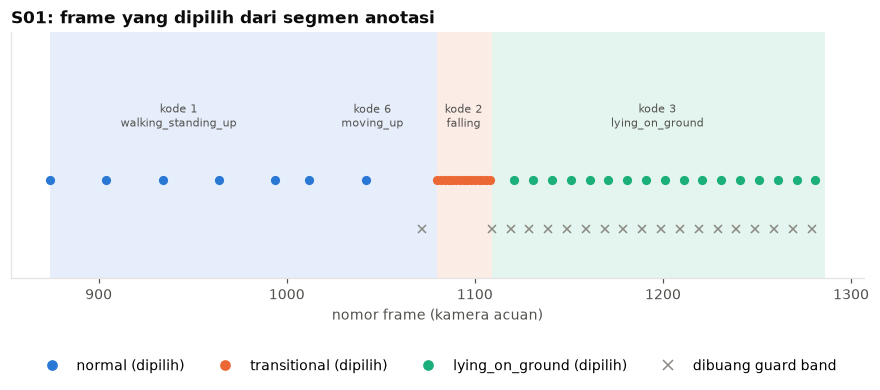

In [9]:
ann = pm.load_annotations(MCF_DIR / "annotations.csv", label_map)
dl = pm.load_delays(MCF_DIR / "frame_delay.csv")

S = 1
segs, ref = ann[S]["segments"], ann[S]["ref_cam"]
strides_mcf, GUARD = {0: 30, 1: 2, 2: 10}, 12
plan = pm.plan_ref_frames(segs, label_map, strides_mcf, GUARD)
plan_no_guard = pm.plan_ref_frames(segs, label_map, strides_mcf, 0)
kept_frames = {f for f, _ in plan}
removed = [(f, c) for f, c in plan_no_guard if f not in kept_frames]
print(f"Skenario S{S:02d}, kamera acuan {ref}, segmen: {segs}")
print(f"Frame terpilih per kelas (stride {strides_mcf}, guard {GUARD}):",
      {CLASS_NAMES[c]: sum(1 for _, k in plan if k == c) for c in (0, 1, 2)})
print(f"Dibuang oleh guard band: {len(removed)} frame")

fig, ax = plt.subplots(figsize=(10, 2.9))
for st, en, code_ in segs:
    k = label_map[code_]
    ax.axvspan(st, en + 1, color=CLASS_COLOR[k], alpha=0.12, lw=0)
    ax.text((st + en) / 2, 1.2, f"kode {code_}\n{etm.CODE_NAMES[code_]}", ha="center", va="bottom",
            fontsize=7.5, color=INK_MUTED)
for f, k in plan:
    ax.plot(f, 1, "o", ms=5, color=CLASS_COLOR[k])
for f, k in removed:
    ax.plot(f, 0.8, "x", ms=5, color="#8a8984")
ax.set_ylim(0.6, 1.6)
ax.set_yticks([])
ax.grid(False)
ax.set_xlabel("nomor frame (kamera acuan)")
ax.set_title(f"S{S:02d}: frame yang dipilih dari segmen anotasi")
handles = [Line2D([], [], marker="o", ls="", color=CLASS_COLOR[k], label=f"{CLASS_NAMES[k]} (dipilih)") for k in (0, 1, 2)]
handles.append(Line2D([], [], marker="x", ls="", color="#8a8984", label="dibuang guard band"))
ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=4, frameon=False)
plt.show()

### 4.2 Sinkronisasi 8 kamera
Label hanya ada di kamera acuan. Nomor frame kamera lain diperoleh dari selisih delay. Indeks video 0-based adalah
`f_cam − base` (`--base 1`, nomor frame pertama pada anotasi). Rumus ini divalidasi visual pada S01 dan S10.

In [10]:
show_source(pm.map_to_cam, pm.split_of)

f_ref = 1100
print(f"Contoh S{S:02d}: frame {f_ref} di kamera acuan (cam{ref}) berpadanan dengan:")
display(pd.DataFrame([{"kamera": c, "delay": dl[S][c - 1], "frame di kamera ini": pm.map_to_cam(f_ref, dl[S], ref, c),
                       "indeks 0-based": pm.map_to_cam(f_ref, dl[S], ref, c) - 1} for c in range(1, 9)]))

def map_to_cam(f_ref, delays, ref_cam, cam):
    """Rumus sinkronisasi yang sudah divalidasi: f_cam = f_ref + d_cam - d_ref."""
    return f_ref + delays[cam - 1] - delays[ref_cam - 1]

def split_of(s, ranges):
    for name, (a, b) in ranges.items():
        if a <= s <= b:
            return name
    return None

Contoh S01: frame 1100 di kamera acuan (cam8) berpadanan dengan:


,kamera,delay,frame di kamera ini,indeks 0-based
0,1,3,1103,1102
1,2,3,1103,1102
2,3,8,1108,1107
3,4,4,1104,1103
4,5,23,1123,1122
5,6,6,1106,1105
6,7,6,1106,1105
7,8,0,1100,1099


### 4.3 Deteksi, filter objek statis, dan pemilihan kotak
Orang berjalan tidak diam di satu kotak, dan orang berbaring tidak punya kotak yang sama dengan orang berdiri.
Kotak yang muncul di tempat **sama** pada ≥ 3 frame normal **dan** ≥ 1 frame lying dianggap benda (rak, tas, kursi),
bukan orang, lalu diabaikan.

In [11]:
show_source(pm.find_static_distractors, pm.pick_box)

def find_static_distractors(classes, dets, iou_thr=0.6, min_normal=3):
    """Cari kotak yang muncul di tempat SAMA pada >= min_normal frame 'normal'
    dan juga pada >= 1 frame 'lying'. Orang berjalan tidak diam di satu kotak,
    dan orang berbaring tidak punya kotak yang sama dengan orang berdiri,
    jadi kotak seperti itu adalah benda (rak, tas, kursi), bukan orang.
    classes: kelas tiap frame; dets: list deteksi tiap frame.
    Return: set (indeks_frame, indeks_deteksi) yang harus diabaikan."""
    clusters = []  # {'rep': (xc,yc,w,h), 'members': [(k, j)]}
    for k, dl in enumerate(dets):
        for j, d in enumerate(dl):
            box = d[1:]
            for cl in clusters:
                if iou_xywh(cl["rep"], box) >= iou_thr:
                    cl["members"].append((k, j))
                    break
            else:
                clusters.append({"rep": box, "members": [(k, j)]})
    bad = set()
    for cl in clusters:
        by_cls = defaultdict(set)
        for k

In [12]:
# ILUSTRASI (data sintetis): deteksi = (conf, xc, yc, w, h). "rak" muncul di tempat yang sama pada frame normal dan lying.
shelf, person_lying = (0.8, 0.5, 0.2, 0.4), (0.5, 0.8, 0.5, 0.15)
person = (0.3, 0.6, 0.15, 0.5)
classes = [0, 0, 0, 0, 2, 2]
dets = [[(0.60, *shelf)], [(0.55, *shelf)], [(0.70, *shelf), (0.90, *person)],
        [(0.50, *shelf)], [(0.62, *shelf)], [(0.48, *person_lying)]]

bad = pm.find_static_distractors(classes, dets)
rows = []
for k, (c, dl_) in enumerate(zip(classes, dets)):
    before = pm.pick_box(dl_, c, 0.25, 0.15)
    after = pm.pick_box([d for j, d in enumerate(dl_) if (k, j) not in bad], c, 0.25, 0.15)
    nama = lambda b: "-" if b is None else ("rak" if b[1:] == shelf else "orang")
    rows.append({"frame": k, "kelas": CLASS_NAMES[c], "kotak tanpa filter": nama(before), "kotak dengan filter": nama(after)})
print("Ilustrasi sintetis, bukan data asli:")
display(pd.DataFrame(rows))

Ilustrasi sintetis, bukan data asli:


,frame,kelas,kotak tanpa filter,kotak dengan filter
0,0,normal,rak,-
1,1,normal,rak,-
2,2,normal,rak,orang
3,3,normal,rak,-
4,4,lying_on_ground,rak,-
5,5,lying_on_ground,orang,orang


Pada ilustrasi, frame lying nomor 4 hanya "melihat" rak; tanpa filter, rak itu akan menjadi label lying. Dengan filter
frame itu dibuang. Konsekuensi yang sama berlaku untuk frame normal yang hanya berisi rak.

### 4.4 Hasil Tahap 2 (dari `ml/data/processed_mcf/dataset_manifest.json`)

In [13]:
mm = read_json(D_MCF / "dataset_manifest.json")
a = mm["args"]
print("Parameter yang dipakai:")
for k in ("normal_stride", "transitional_stride", "lying_stride", "guard", "base", "train", "val", "test",
          "ref_only", "detector", "imgsz", "conf", "conf_hard", "batch", "no_static_filter"):
    print(f"  {k:<20}: {a[k]}")
print(f"  kamera              : {a['cams']}   skenario: {a['scenarios'][0]}..{a['scenarios'][-1]}")

rows = [{"split": k.split("/", 1)[0], "kelas": k.split("/", 1)[1], "frame": v["frames"], "skenario": len(v["scenarios"])}
        for k, v in mm["counts"].items()]
t2 = pd.DataFrame(rows)
print("\nFrame per split x kelas:")
display(t2.pivot(index="split", columns="kelas", values="frame").reindex(index=list(SPLITS), columns=CLASS_ORDER))
print("Jumlah skenario per split x kelas:")
display(t2.pivot(index="split", columns="kelas", values="skenario").reindex(index=list(SPLITS), columns=CLASS_ORDER))

kept_total = sum(v[0] for v in mm["retention_per_cam"].values())
cand_total = sum(v[1] for v in mm["retention_per_cam"].values())
print(f"\nKandidat setelah stride + sinkronisasi: {cand_total}  ->  tersimpan: {kept_total}")
assert kept_total == t2.frame.sum()
print("Dibuang karena detektor tidak menemukan orang:", mm["dropped_no_detection"])
print("Frame yang kotaknya diubah oleh filter objek statis:", mm["box_changed_by_static_filter"])
print("Dibuang karena di luar rentang video:", mm["dropped_out_of_range"] or 0, "| video hilang:", mm["missing_videos"] or 0)
print(f"S24 hanya memakai kamera acuan (cam{ann[24]['ref_cam']}), sesuai --ref-only {a['ref_only']}.")

ret = {}
for key, (kp, cd) in mm["retention_per_cam"].items():
    cam, cls = key.split("/")
    ret.setdefault(cls, {})[cam] = f"{kp}/{cd} ({100 * kp / cd:.0f}%)" if cd else "-"
print("\nRetensi per kamera (tersimpan / kandidat) — cari kamera yang 'hilang':")
display(pd.DataFrame(ret).T.reindex(CLASS_ORDER))

Parameter yang dipakai:
  normal_stride       : 30
  transitional_stride : 2
  lying_stride        : 10
  guard               : 12
  base                : 1
  train               : [1, 16]
  val                 : [17, 20]
  test                : [21, 24]
  ref_only            : [24]
  detector            : yolo11m.pt
  imgsz               : 960
  conf                : 0.25
  conf_hard           : 0.15
  batch               : 16
  no_static_filter    : False
  kamera              : [1, 2, 3, 4, 5, 6, 7, 8]   skenario: 1..24

Frame per split x kelas:


kelas,normal,transitional,lying_on_ground
split,,,
train,972,1869,681
val,318,923,170
test,1357,453,134


Jumlah skenario per split x kelas:


kelas,normal,transitional,lying_on_ground
split,,,
train,16,16,16
val,4,4,4
test,4,3,2



Kandidat setelah stride + sinkronisasi: 9723  ->  tersimpan: 6877
Dibuang karena detektor tidak menemukan orang: {'transitional': 1083, 'lying_on_ground': 1023, 'normal': 740}
Frame yang kotaknya diubah oleh filter objek statis: {'normal': 54, 'transitional': 97, 'lying_on_ground': 31}
Dibuang karena di luar rentang video: 0 | video hilang: 0
S24 hanya memakai kamera acuan (cam6), sesuai --ref-only [24].

Retensi per kamera (tersimpan / kandidat) — cari kamera yang 'hilang':


,cam1,cam2,cam3,cam4,cam5,cam6,cam7,cam8
normal,304/409 (74%),309/409 (76%),326/409 (80%),327/409 (80%),343/409 (84%),404/524 (77%),294/409 (72%),340/409 (83%)
transitional,401/541 (74%),446/541 (82%),422/541 (78%),355/541 (66%),411/541 (76%),341/541 (63%),426/541 (79%),443/541 (82%)
lying_on_ground,133/251 (53%),186/251 (74%),74/251 (29%),72/251 (29%),172/251 (69%),114/251 (45%),141/251 (56%),93/251 (37%)


## 5. Tahap 3 — Penggabungan (`merge_datasets.py`)

**Aturan:**
- Split **tidak diacak ulang**: train/val/test tiap sumber tetap di split-nya (sudah dibuat per video/skenario).
- **Pengecualian opsional** `--mcf-split`: memindahkan file MCF antar-split **per skenario** tanpa menjalankan ulang
  `prepare_mcf.py` yang lama. Harus menutup skenario 1–24 tanpa tumpang tindih.
- Nama file harus unik (prefiks `urfall_` / `mcf_`); bentrok → berhenti.
- Setiap label divalidasi: 5 kolom, kelas 0..2, koordinat 0..1. File yang rusak dilewati dan dicatat.
- File ditautkan keras (*hard link*) bila memungkinkan agar hemat disk.

In [14]:
mg = load_script("merge_datasets")
show_source(mg.check_label, mg.parse_mcf_split)

def check_label(path: Path) -> int:
    lines = [l for l in path.read_text().splitlines() if l.strip()]
    if not lines:
        raise ValueError("label kosong")
    cls = None
    for l in lines:
        p = l.split()
        if len(p) != 5:
            raise ValueError(f"harus 5 kolom: {l!r}")
        c = int(p[0])
        v = list(map(float, p[1:]))
        if c not in CLASS_NAMES or not all(0.0 <= x <= 1.0 for x in v):
            raise ValueError(f"nilai tidak valid: {l!r}")
        cls = c if cls is None else cls
    return cls

def parse_mcf_split(text):
    """'train=1-14,val=15-18,test=19-24' -> {scenario: split}. Wajib menutup 1..24 tanpa tumpang tindih."""
    m = {}
    for part in text.split(","):
        name, rng = part.split("=")
        name = name.strip()
        if name not in SPLITS:
            sys.exit(f"[FATAL] nama split tidak dikenal: {name!r}")
        a, b = map(int, rng.split("-"))
        for sc in range(a, b + 1):
            if sc in m:
                s

In [15]:
v2 = read_json(D_V2 / "dataset_manifest.json")
rows = [dict(zip(("sumber", "split", "kelas"), k.split("/")), frame=n) for k, n in v2["counts"].items()]
idx = pd.MultiIndex.from_product([["processed", "processed_mcf"], SPLITS], names=["sumber", "split"])
tv2 = (pd.DataFrame(rows).pivot_table(index=["sumber", "split"], columns="kelas", values="frame", aggfunc="sum")
       .reindex(index=idx, columns=CLASS_ORDER))
print("processed_v2 — frame per sumber x split x kelas (dari manifest):")
display(tv2)
print("File dilewati:", v2["skipped"] or 0)

meta = pd.read_csv(D_V2 / "frames_meta.csv")
assert len(meta) == tv2.values.sum()
print(f"Total frame processed_v2: {len(meta)}  (= {n_saved} UR Fall + {kept_total} MCF)")

processed_v2 — frame per sumber x split x kelas (dari manifest):


kelas                normal  transitional  lying_on_ground
sumber        split                                       
processed     train    1016           743              256
              val       129           255               91
              test      197           315               63
processed_mcf train     718          1585              619
              val       449           515              114
              test     1480          1145              252

File dilewati: 0
Total frame processed_v2: 9942  (= 3065 UR Fall + 6877 MCF)


### 5.1 Pembagian skenario MCF yang sebenarnya berlaku

`merge_datasets.py` **tidak mencatat** nilai `--mcf-split` di manifest-nya. Namun pembagian yang berlaku bisa
dibaca dari `frames_meta.csv` (tiap frame MCF membawa nomor skenario dan split-nya).

In [16]:
mcf_rows = meta[meta.group == "mcf"].copy()
mcf_rows["skenario"] = mcf_rows.video.str[1:].astype(int)
actual = mcf_rows.groupby("skenario").split.first().to_dict()
orig = {int(k): v for k, v in mm["scenario_split"].items()}

def to_ranges(mapping):
    out = []
    for sp in SPLITS:
        sc = sorted(s for s, v in mapping.items() if v == sp)
        assert sc == list(range(sc[0], sc[-1] + 1)), "tidak berurutan"
        out.append(f"{sp}={sc[0]}-{sc[-1]}")
    return ",".join(out)

print("Default prepare_mcf.py (processed_mcf):", to_ranges(orig))
print("Yang berlaku di processed_v2          :", to_ranges(actual), " <- setara --mcf-split")
print("Skenario yang berpindah split:",
      {s: f"{orig[s]} -> {actual[s]}" for s in sorted(actual) if actual[s] != orig[s]})

leak = (meta.groupby(["group", "video"]).split.nunique() > 1).sum()
print(f"\nVideo/skenario yang muncul di lebih dari satu split: {leak}  (harus 0)")

Default prepare_mcf.py (processed_mcf): train=1-16,val=17-20,test=21-24
Yang berlaku di processed_v2          : train=1-14,val=15-18,test=19-24  <- setara --mcf-split
Skenario yang berpindah split: {15: 'train -> val', 16: 'train -> val', 19: 'val -> test', 20: 'val -> test'}

Video/skenario yang muncul di lebih dari satu split: 0  (harus 0)


## 6. Tahap 4 — Audit (`audit_dataset.py`)

Audit **read-only**: tidak mengubah gambar maupun label, hanya menulis `frames_meta.csv` (satu baris per frame:
sumber, video, kamera, nomor frame, kelas, kode MCF, posisi dalam segmen, ukuran kotak). Tujuh pertanyaan yang dijawab
sebelum training, tiap poin menentukan keputusan tahap berikutnya:

1. Kelas × sumber × split: ada kelas yang hanya hidup di satu domain? Seberapa dominan transitional?
2. Frame `lying` dari ADL UR Fall: orang berbaring di sofa/kasur (bukan jatuh)?
3. Komposisi normal MCF per kode (kode 8 sofa, duduk, jongkok = *hard negative*).
4. Posisi frame transitional di dalam segmennya (awal / tengah / akhir).
5. Kebocoran: satu video/skenario tidak boleh ada di dua split.
6. Ukuran dan rasio kotak per kelas × sumber (pembeda domain).
7. Durasi segmen lying per video (apakah aturan alarm 10 detik bisa diuji).

Sel di bawah **menghitung ulang** isi audit dari `frames_meta.csv` tanpa menjalankan skrip (agar tidak menimpa berkas).

In [17]:
mtr = meta.assign(kelas=meta.cls.map(CLASS_NAMES))

print("=== 1. Frame per sumber x split x kelas ===")
GROUPS = ["urfall-fall", "urfall-adl", "mcf"]
IDX = pd.MultiIndex.from_product([GROUPS, SPLITS], names=["group", "split"])
t = (mtr.pivot_table(index=["group", "split"], columns="kelas", values="stem", aggfunc="count")
     .reindex(index=IDX, columns=CLASS_ORDER).fillna(0).astype(int))
display(t)
print("Jumlah video/skenario per sumber x split x kelas:")
display(mtr.pivot_table(index=["group", "split"], columns="kelas", values="video", aggfunc="nunique")
        .reindex(index=IDX, columns=CLASS_ORDER).fillna(0).astype(int))

share = mtr.pivot_table(index="kelas", columns="group", values="stem", aggfunc="count", fill_value=0)
share = (100 * share.div(share.sum(axis=1), axis=0)).round(0).astype(int).reindex(CLASS_ORDER)
print("Porsi sumber di tiap kelas (%):")
display(share)

print("=== 2. Frame lying dari sequence ADL UR Fall (orang bukan jatuh) ===")
adl = meta[(meta.group == "urfall-adl") & (meta.cls == 2)].groupby("video").size()
print(", ".join(f"{k}: {v}" for k, v in adl.items()) or "tidak ada")

print("\n=== 3. Frame normal MCF per kode anotasi ===")
mn = meta[(meta.group == "mcf") & (meta.cls == 0)].dropna(subset=["code"]).assign(
    kode=lambda d: d.code.astype(int))
display(mn.pivot_table(index="kode", columns="split", values="stem", aggfunc="count", fill_value=0)
        .reindex(columns=list(SPLITS)))

print("=== 4. Posisi frame transitional di dalam segmennya ===")
tr = meta[(meta.cls == 1) & meta.seg_pos.notna()].copy()
tr["bagian"] = pd.cut(tr.seg_pos, [-0.001, 1 / 3, 2 / 3, 1.0], labels=["awal", "tengah", "akhir"])
display((100 * pd.crosstab(tr.group, tr.bagian, normalize="index")).round(0).astype(int))

print("=== 5. Kebocoran antar-split ===")
print("video/skenario di >1 split:", int(leak))

print("\n=== 6. Median ukuran kotak (lebar, tinggi, rasio w/h) ===")
bx = meta.groupby(["cls", "group"]).agg(w=("w", "median"), h=("h", "median"), n=("stem", "count"))
bx["w/h"] = bx.w / bx.h
bx.index = pd.MultiIndex.from_tuples([(CLASS_NAMES[c], g) for c, g in bx.index], names=["kelas", "sumber"])
display(bx.round(2))

=== 1. Frame per sumber x split x kelas ===


kelas              normal  transitional  lying_on_ground
group       split                                       
urfall-fall train     196           586              183
            val        19            96               14
            test       34           127               12
urfall-adl  train     820           157               73
            val       110           159               77
            test      163           188               51
mcf         train     718          1585              619
            val       449           515              114
            test     1480          1145              252

Jumlah video/skenario per sumber x split x kelas:


kelas              normal  transitional  lying_on_ground
group       split                                       
urfall-fall train      21            21               19
            val         4             4                3
            test        5             5                2
urfall-adl  train      28             5                5
            val         6             5                4
            test        6             6                6
mcf         train      14            14               14
            val         4             4                4
            test        6             5                4

Porsi sumber di tiap kelas (%):


...

split,train,val,test
kode,,,
1,524,124,1018
4,0,18,75
5,55,112,117
6,82,108,162
7,15,87,57
8,42,0,51


=== 4. Posisi frame transitional di dalam segmennya ===


bagian,awal,tengah,akhir
group,,,
mcf,40,32,27
urfall-adl,35,30,35
urfall-fall,34,32,34


=== 5. Kebocoran antar-split ===
video/skenario di >1 split: 0

=== 6. Median ukuran kotak (lebar, tinggi, rasio w/h) ===


w     h     n   w/h
kelas           sumber                             
normal          mcf          0.12  0.31  2647  0.40
                urfall-adl   0.17  0.55  1093  0.31
                urfall-fall  0.18  0.61   249  0.29
transitional    mcf          0.14  0.30  3245  0.49
                urfall-adl   0.20  0.39   504  0.52
                urfall-fall  0.28  0.50   809  0.57
lying_on_ground mcf          0.20  0.23   985  0.89
                urfall-adl   0.25  0.27   201  0.93
                urfall-fall  0.41  0.29   209  1.40

In [18]:
print("=== 7. Durasi segmen lying per video ===")
FPS = 30.0   # ASUMSI di audit_dataset.py (belum diverifikasi), dipakai untuk menerjemahkan frame ke detik
dur = {"mcf": [], "urfall-fall": [], "urfall-adl": []}
for sc, d in ann.items():
    tot = sum(en - st + 1 for st, en, code_ in d["segments"] if code_ == 3)
    if tot:
        dur["mcf"].append(tot)
ly = meta[meta.cls == 2].groupby(["group", "video"]).frame.agg(lambda s: s.max() - s.min() + 1)
for g in ("urfall-fall", "urfall-adl"):
    dur[g] = ly[g].tolist() if g in ly.index.get_level_values(0) else []
rows = []
for g, v in dur.items():
    if v:
        v = sorted(v)
        rows.append({"sumber": g, "video": len(v), "min (detik)": v[0] / FPS, "median (detik)": v[len(v) // 2] / FPS,
                     "maks (detik)": v[-1] / FPS, "video >= 10 detik": f"{sum(x / FPS >= 10 for x in v)}/{len(v)}"})
display(pd.DataFrame(rows).round(1))
print(f"(Asumsi {FPS:g} FPS; MCF dihitung dari anotasi kode 3 di kamera acuan, UR Fall dari rentang frame lying yang tersimpan.)")

=== 7. Durasi segmen lying per video ===


,sumber,video,min (detik),median (detik),maks (detik),video >= 10 detik
0,mcf,22,1.0,4.1,6.9,0/22
1,urfall-fall,24,0.0,0.6,2.0,0/24
2,urfall-adl,15,0.0,1.7,6.0,0/15


(Asumsi 30 FPS; MCF dihitung dari anotasi kode 3 di kamera acuan, UR Fall dari rentang frame lying yang tersimpan.)


Dengan asumsi 30 FPS, **tidak ada** video yang memuat lying ≥ 10 detik pada tabel nomor 7 di atas. Jadi aturan alarm
10 detik tidak dapat diuji dari frame lying yang tersimpan di dataset ini (untuk UR Fall angkanya bahkan merupakan
batas bawah, karena dihitung dari frame yang lolos stride dan deteksi).

Audit juga dapat membuat **gambar kontak** untuk pemeriksaan visual (argumen `--sheet-*`). Berikut gambar kontak
frame `lying` dari sequence ADL UR Fall yang sudah dihasilkan, dipakai untuk menilai apakah itu orang berbaring di
sofa/kasur atau memang terkapar.

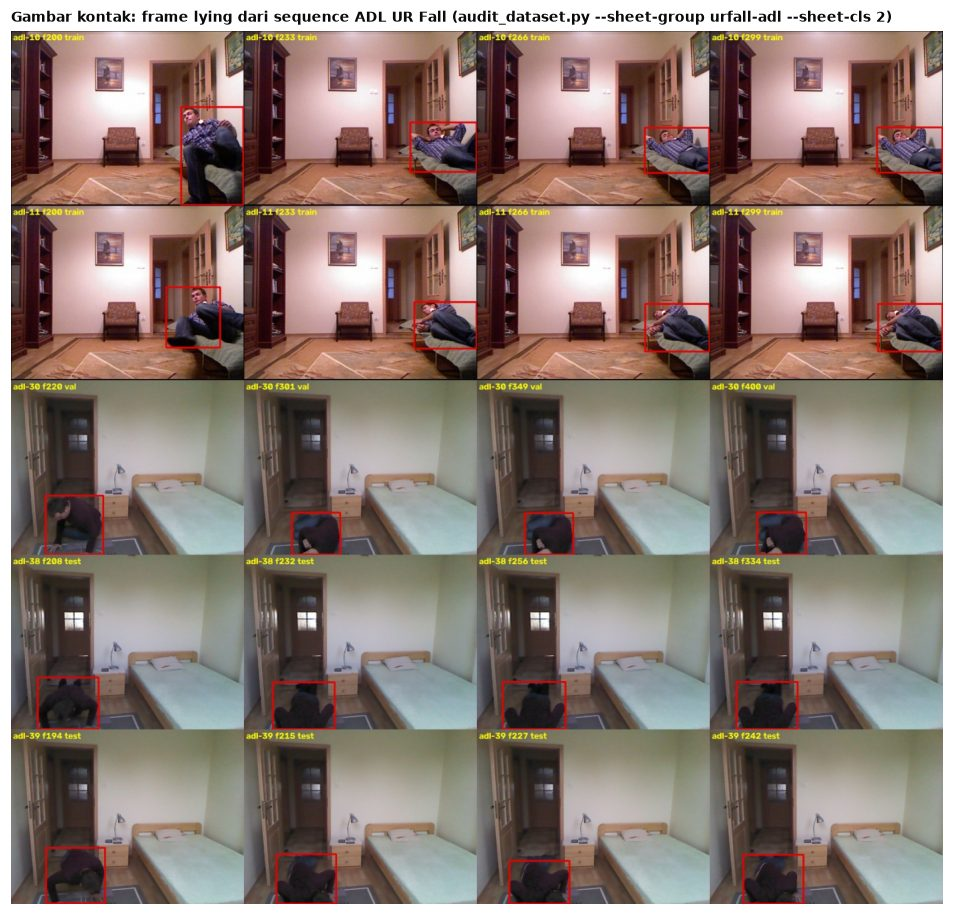

In [19]:
sheet = D_V2 / "sheet_urfall-adl_c2.jpg"
if sheet.exists():
    img = cv2.cvtColor(cv2.imread(str(sheet)), cv2.COLOR_BGR2RGB)
    h, w = img.shape[:2]
    if w > 1400:
        img = cv2.resize(img, (1400, int(h * 1400 / w)), interpolation=cv2.INTER_AREA)
    fig, ax = plt.subplots(figsize=(11, 11 * img.shape[0] / img.shape[1]))
    ax.imshow(img)
    ax.axis("off")
    ax.set_title("Gambar kontak: frame lying dari sequence ADL UR Fall (audit_dataset.py --sheet-group urfall-adl --sheet-cls 2)", fontsize=9)
    plt.show()
else:
    print("gambar kontak tidak ditemukan:", rel(sheet))

**Pengamatan dari gambar kontak di atas** (pembacaan visual, bukan keluaran skrip): pada adl-10 dan adl-11 orang
memang berbaring di sofa, sehingga wajar dijadikan *normal*. Pada adl-30, adl-38, dan adl-39 orang tampak
berlutut atau merangkak di lantai dekat tempat tidur, sehingga label `lying` dari CSV UR Fall tidak mencerminkan postur
berbaring. Frame seperti ini ambigu, dan itulah yang dibuang pada Tahap 5.

## 7. Tahap 5 — Dataset training final (`make_training_set.py`)

Membuat dataset final dari `processed_v2` memakai `frames_meta.csv`. Pada konfigurasi yang dipakai proyek ini
(**3 kelas**, `--keep-transitional`):

| Keputusan | Aturan |
|---|---|
| Kelas | tetap 3: normal, transitional, lying_on_ground |
| Frame lying dari **ADL** UR Fall di `--adl-lying-normal` | dijadikan **normal** (berbaring di sofa/kasur, bukan jatuh) |
| Frame lying dari ADL di `--adl-lying-drop` | **dibuang** (dinilai ambigu) |
| Sequence ADL berisi lying lainnya | tetap **lying** |
| Subsampling transitional | **hanya di train**, acak dengan seed tetap, fraksi `--transitional-keep-frac` |
| val/test | **tidak pernah** disubsampel |

Ultralytics tidak punya bobot per kelas, jadi mitigasi ketimpangan dilakukan di level data. Skrip juga menyediakan
mode 2 kelas (normal vs lying, transitional dibuang) untuk uji A/B di Kaggle.

In [20]:
mts = load_script("make_training_set")
show_source(mts.new_class)

def new_class(row, adl_normal, adl_drop, keep_trans):
    """-> kelas baru atau None bila frame dibuang."""
    cls, group, video = int(row["cls"]), row["group"], row["video"]
    lying = 2 if keep_trans else 1
    if cls == 1:
        return 1 if keep_trans else None
    if cls == 0:
        return 0
    # cls == 2 (lying)
    if group == "urfall-adl":
        if video in adl_drop:
            return None
        if video in adl_normal:
            return 0
    return lying



In [21]:
fin = read_json(D_FINAL / "dataset_manifest.json")
names = fin["classes"]
print("Parameter dari manifest:")
for k in ("keep_transitional", "transitional_keep_frac", "seed", "adl_lying_normal", "adl_lying_drop"):
    print(f"  {k:<24}: {fin[k]}")
print("Dibuang:", fin["dropped"])

# Replikasi aturan dari frames_meta.csv (tanpa menulis berkas), lalu bandingkan dengan manifest
rng = random.Random(fin["seed"])
cand = sorted(meta.loc[(meta.split == "train") & (meta.cls == 1), "stem"])
n_keep = round(len(cand) * fin["transitional_keep_frac"])
skip = set(cand) - set(rng.sample(cand, n_keep))
rep, drp = Counter(), Counter()
for r in meta.to_dict("records"):
    nc = mts.new_class(r, set(fin["adl_lying_normal"]), set(fin["adl_lying_drop"]), fin["keep_transitional"])
    if nc is None:
        drp["transitional" if r["cls"] == 1 else "lying ADL dibuang"] += 1
        continue
    if r["stem"] in skip:
        drp["transitional (disubsampel di train)"] += 1
        continue
    rep[f"{r['group']}/{r['split']}/{names[str(nc)]}"] += 1

print("\nReplikasi hitungan identik dengan manifest:", dict(rep) == fin["counts"] and dict(drp) == fin["dropped"])
assert dict(rep) == fin["counts"]

Parameter dari manifest:
  keep_transitional       : True
  transitional_keep_frac  : 0.5
  seed                    : 0
  adl_lying_normal        : ['adl-10', 'adl-11']
  adl_lying_drop          : ['adl-21', 'adl-22', 'adl-23', 'adl-30', 'adl-32', 'adl-33', 'adl-34', 'adl-35', 'adl-36', 'adl-37', 'adl-38', 'adl-39', 'adl-40']
Dibuang: {'transitional (disubsampel di train)': 1164, 'lying ADL dibuang': 133}

Replikasi hitungan identik dengan manifest: True


Dataset training FINAL (ml/data/processed_v2_3cls): frame per dataset x split x kelas


kelas                       normal  transitional  lying_on_ground
dataset              split                                       
UR Fall (fall + ADL) train    1084           379              183
                     val       129           255               14
                     test      197           315               12
MCF                  train     718           785              619
                     val       449           515              114
                     test     1480          1145              252

Komposisi kelas per split (%), total frame, dan porsi MCF:


kelas,normal,transitional,lying_on_ground,total frame,porsi MCF (%)
split,,,,,
train,48.0,31.0,21.0,3768,56.0
val,39.0,52.0,9.0,1476,73.0
test,49.0,43.0,8.0,3401,85.0


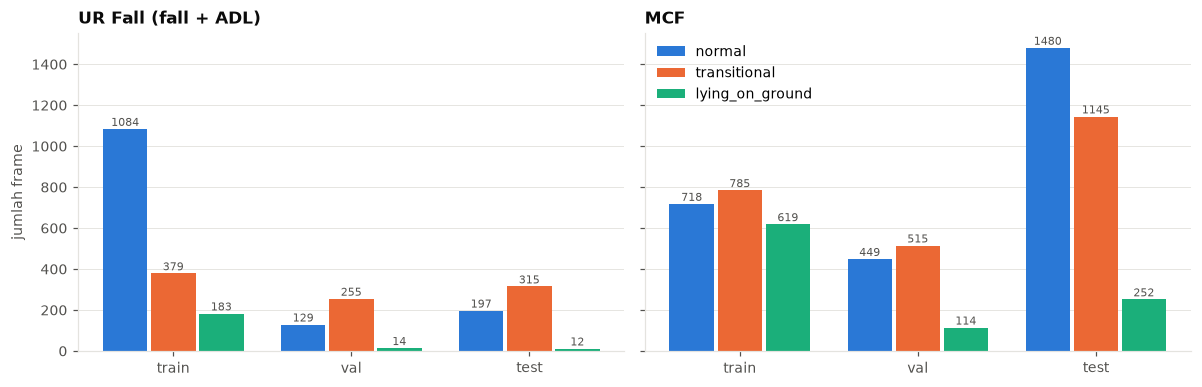

In [22]:
rows = [dict(zip(("sumber", "split", "kelas"), k.split("/")), frame=n) for k, n in fin["counts"].items()]
fdf = pd.DataFrame(rows)
fdf["dataset"] = np.where(fdf.sumber == "mcf", "MCF", "UR Fall (fall + ADL)")
DS = ["UR Fall (fall + ADL)", "MCF"]
agg = (fdf.groupby(["dataset", "split", "kelas"]).frame.sum().unstack("kelas")
       .reindex(index=pd.MultiIndex.from_product([DS, SPLITS], names=["dataset", "split"]), columns=CLASS_ORDER)
       .fillna(0).astype(int))

print("Dataset training FINAL (ml/data/processed_v2_3cls): frame per dataset x split x kelas")
display(agg)

tot = agg.groupby("split").sum().reindex(list(SPLITS))
pct = (100 * tot.div(tot.sum(axis=1), axis=0)).round(0)
pct["total frame"] = tot.sum(axis=1)
pct["porsi MCF (%)"] = (100 * agg.loc["MCF"].sum(axis=1) / tot.sum(axis=1)).round(0)
print("Komposisi kelas per split (%), total frame, dan porsi MCF:")
display(pct)

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, ds in zip(axes, DS):
    x = np.arange(len(SPLITS))
    for i, (k, nm) in enumerate(CLASS_NAMES.items()):
        vals = agg.loc[ds, nm].reindex(list(SPLITS)).values
        bars = ax.bar(x + (i - 1) * 0.27, vals, width=0.25, color=CLASS_COLOR[k], label=nm)
        for b, v in zip(bars, vals):
            ax.text(b.get_x() + b.get_width() / 2, v + 15, f"{v}", ha="center", fontsize=7, color=INK_MUTED)
    ax.set_xticks(x)
    ax.set_xticklabels(SPLITS)
    ax.set_title(ds)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("jumlah frame")
axes[1].legend(loc="upper left", frameon=False, ncol=1)
plt.tight_layout()
plt.show()

### 7.1 Contoh frame dataset final (train, dengan kotak anotasi)
Satu contoh per sumber × kelas, diambil dari tengah daftar berurutan agar tidak selalu frame pertama.

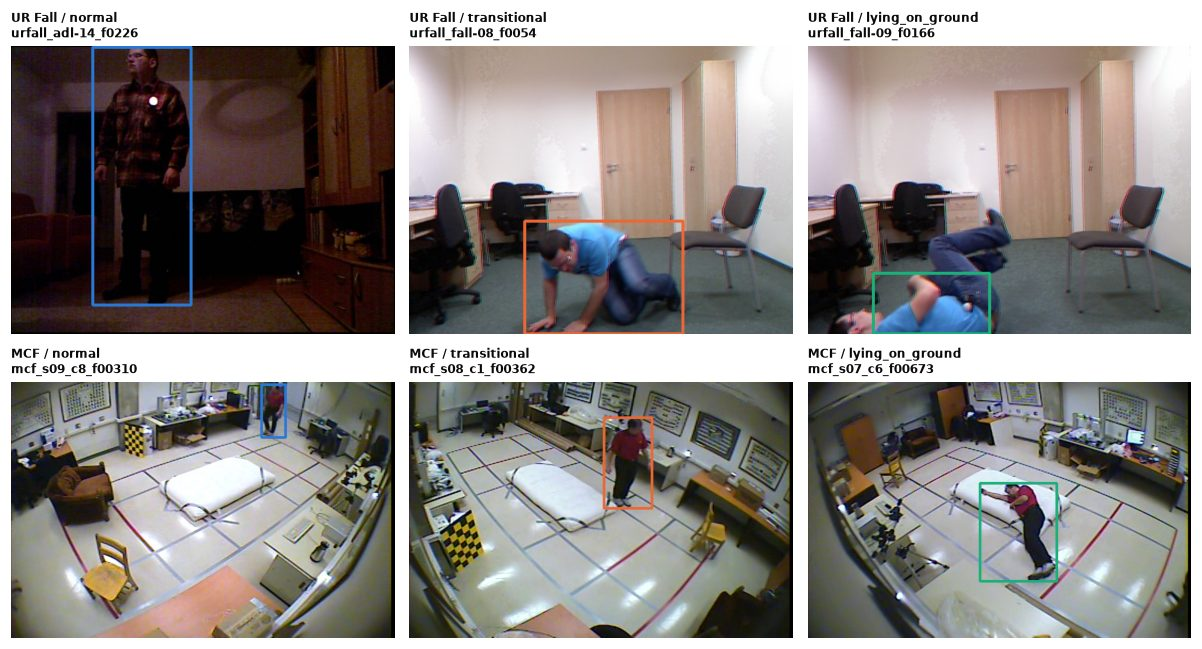

In [23]:
def hex_to_bgr(h):
    h = h.lstrip("#")
    return tuple(int(h[i:i + 2], 16) for i in (4, 2, 0))


def pick(prefix, cls):
    hits = []
    for lf in sorted((D_FINAL / "labels" / "train").glob(f"{prefix}*.txt")):
        p = lf.read_text().split()
        if int(p[0]) == cls:
            hits.append((lf, [float(x) for x in p[1:5]]))
    return hits[len(hits) // 2] if hits else None


fig, axes = plt.subplots(2, 3, figsize=(11, 6.2))
for r, (prefix, title) in enumerate((("urfall_", "UR Fall"), ("mcf_", "MCF"))):
    for c in (0, 1, 2):
        ax = axes[r][c]
        ax.axis("off")
        hit = pick(prefix, c)
        if hit is None:
            continue
        lf, (xc, yc, w, h) = hit
        img = cv2.imread(str(D_FINAL / "images" / "train" / f"{lf.stem}.jpg"))
        if img is None:          # gambar tidak ada di mesin ini (data tidak ikut di-commit)
            ax.set_title(f"{title} / {CLASS_NAMES[c]}: gambar tidak ditemukan", fontsize=8, loc="left")
            continue
        H, W = img.shape[:2]
        cv2.rectangle(img, (int((xc - w / 2) * W), int((yc - h / 2) * H)),
                      (int((xc + w / 2) * W), int((yc + h / 2) * H)), hex_to_bgr(CLASS_COLOR[c]), 4)
        ax.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
        ax.set_title(f"{title} / {CLASS_NAMES[c]}\n{lf.stem}", fontsize=8, loc="left")
plt.tight_layout()
plt.show()

## 8. Ringkasan konfigurasi aktual

Karena belum ada satu berkas konfigurasi, tabel berikut menghimpun semua parameter dari manifest tiap tahap, dan
menghasilkan perintah untuk mengulang tahap tersebut (dibangun dari manifest agar tidak salah ketik).

In [24]:
cfg = []
def add(tahap, **kw):
    cfg.extend({"tahap": tahap, "parameter": k, "nilai": v} for k, v in kw.items())

add("1 prepare_dataset", normal_stride=p["normal_stride"], transitional_stride=1, lying_stride=p["lying_stride"],
    detector=p["detector"], conf_normal=p["conf"], conf_hard=p["conf_hard"],
    split_fall="1-21 / 22-25 / 26-30", split_adl="1-28 / 29-34 / 35-40", jpg_quality=95)
add("2 prepare_mcf", normal_stride=a["normal_stride"], transitional_stride=a["transitional_stride"],
    lying_stride=a["lying_stride"], guard=a["guard"], detector=a["detector"], imgsz=a["imgsz"],
    conf_normal=a["conf"], conf_hard=a["conf_hard"], ref_only=a["ref_only"], base=a["base"],
    static_filter=not a["no_static_filter"], split_awal=f"{a['train']} / {a['val']} / {a['test']}")
add("3 merge_datasets", sumber="processed + processed_mcf", mcf_split=to_ranges(actual) + "  (diturunkan dari frames_meta.csv)")
add("5 make_training_set", keep_transitional=fin["keep_transitional"], transitional_keep_frac=fin["transitional_keep_frac"],
    seed=fin["seed"], adl_lying_normal=fin["adl_lying_normal"], adl_lying_drop=fin["adl_lying_drop"])
display(pd.DataFrame(cfg))

print("\nPerintah untuk mengulang tiap tahap (dari root repo):")
print("# 0  python ml/scripts/extract_mcf_tables.py --report technicalReport_dataset.pdf --out-dir ml/data/mcf")
print('# 1  python ml/scripts/prepare_dataset.py --raw-dir "<folder raw UR Fall>" --output-dir ml/data/processed '
      f'--normal-stride {p["normal_stride"]} --lying-stride {p["lying_stride"]}')
print(f'# 2  python ml/scripts/prepare_mcf.py --root ml/data/mcf/dataset --output-dir ml/data/processed_mcf '
      f'--detector {a["detector"]} --imgsz {a["imgsz"]} --force')
print(f'# 3  python ml/scripts/merge_datasets.py --src ml/data/processed ml/data/processed_mcf '
      f'--output-dir ml/data/processed_v2 --mcf-split "{to_ranges(actual)}"')
print("# 4  python ml/scripts/audit_dataset.py --dataset ml/data/processed_v2")
print("# 5  python ml/scripts/make_training_set.py --dataset ml/data/processed_v2 --output-dir ml/data/processed_v2_3cls "
      f'--keep-transitional --transitional-keep-frac {fin["transitional_keep_frac"]} --seed {fin["seed"]} '
      f'--adl-lying-normal {" ".join(fin["adl_lying_normal"])} --adl-lying-drop {" ".join(fin["adl_lying_drop"])}')

,tahap,parameter,nilai
0,1 prepare_dataset,normal_stride,5
1,1 prepare_dataset,transitional_stride,1
2,1 prepare_dataset,lying_stride,3
3,1 prepare_dataset,detector,yolo11n.pt
4,1 prepare_dataset,conf_normal,0.25
5,1 prepare_dataset,conf_hard,0.15
6,1 prepare_dataset,split_fall,1-21 / 22-25 / 26-30
7,1 prepare_dataset,split_adl,1-28 / 29-34 / 35-40
8,1 prepare_dataset,jpg_quality,95
9,2 prepare_mcf,normal_stride,30



Perintah untuk mengulang tiap tahap (dari root repo):
# 0  python ml/scripts/extract_mcf_tables.py --report technicalReport_dataset.pdf --out-dir ml/data/mcf
# 1  python ml/scripts/prepare_dataset.py --raw-dir "<folder raw UR Fall>" --output-dir ml/data/processed --normal-stride 5 --lying-stride 3
# 2  python ml/scripts/prepare_mcf.py --root ml/data/mcf/dataset --output-dir ml/data/processed_mcf --detector yolo11m.pt --imgsz 960 --force
# 3  python ml/scripts/merge_datasets.py --src ml/data/processed ml/data/processed_mcf --output-dir ml/data/processed_v2 --mcf-split "train=1-14,val=15-18,test=19-24"
# 4  python ml/scripts/audit_dataset.py --dataset ml/data/processed_v2
# 5  python ml/scripts/make_training_set.py --dataset ml/data/processed_v2 --output-dir ml/data/processed_v2_3cls --keep-transitional --transitional-keep-frac 0.5 --seed 0 --adl-lying-normal adl-10 adl-11 --adl-lying-drop adl-21 adl-22 adl-23 adl-30 adl-32 adl-33 adl-34 adl-35 adl-36 adl-37 adl-38 adl-39 adl-40


## 9. Catatan dan keterbatasan pipeline saat ini

Bagian ini mencatat **fakta yang terbaca dari kode dan manifest**. Tidak ada perubahan yang diterapkan; ini hanya
bahan agar pembaca dokumen tahu batas data yang dipakai.

1. **Bukan satu skrip dan satu konfigurasi.** Lima skrip dengan argumen CLI sendiri; parameter hanya terekam di manifest.
   Nilai `--mcf-split` pada Tahap 3 **tidak tercatat**; bagian 5.1 menurunkannya dari `frames_meta.csv`.
2. **Kebijakan bbox berbeda antar sumber.** UR Fall: `yolo11n`, resolusi bawaan, kotak **conf tertinggi**.
   MCF: `yolo11m`, `imgsz 960`, kotak **terbesar** setelah filter objek statis. Kualitas dan gaya anotasi kotak
   kedua sumber karenanya tidak identik.
3. **Frame tanpa deteksi dibuang.** UR Fall: 397 lying, 406 transitional, 241 normal. MCF: 1023 lying, 1083 transitional,
   740 normal (angka dari manifest). Yang hilang cenderung pose sulit (berbaring, sedang jatuh), jadi dataset condong ke
   contoh yang mudah dideteksi.
4. **Kepadatan sampling berbeda.** UR Fall stride 5/1/3 pada satu kamera; MCF stride 30/2/10 pada 8 kamera. Satu
   momen MCF dapat muncul hingga 8 kali dari sudut berbeda, sehingga jumlah sampel independen lebih kecil dari angka mentah.
5. **Guard band hanya ada di MCF**; batas kelas di UR Fall tidak dipangkas.
6. **Sinkronisasi kamera MCF divalidasi visual pada S01 dan S10.** Segmen transitional hanya sekitar 38 frame
   (median), sehingga selisih beberapa frame pada kamera lain berdampak besar pada label transitional.
7. **Keputusan ADL.** adl-10 dan adl-11 dijadikan normal; 13 sequence lain dibuang. Karena frame lying dari adl-35 sampai 40
   (test) ikut dibuang, **split test UR Fall tidak memuat frame ADL-berbaring** (lihat tabel bagian 7).
8. **Komposisi test.** Sebagian besar frame test berasal dari MCF (kolom *porsi MCF* di bagian 7), dan transitional
   di-oversample oleh stride, sehingga proporsi kelas val/test tidak mencerminkan frekuensi nyata di lapangan.
9. **Asumsi FPS 30** dipakai untuk menerjemahkan frame ke detik pada audit; belum diverifikasi di skrip.
10. **Pipeline awal** (`prepare_urfall.py`: dedup pHash/dHash, satu sumber, 1.498 gambar) digantikan oleh Tahap 1.
    Dokumen `DATA_PREPROCESSING.md` di `origin/ml-modeling` masih menjelaskan pipeline awal itu.